In [5]:
import numpy as np
import h5py

# Initialize a list to store filtered data for each channel
residu_data = [[] for _ in range(6)]
lon_data = [[] for _ in range(6)]
lat_data = [[] for _ in range(6)]

file_path = f"20250116_PJ1to61_CH1toCH6.h5"
        
# Loop over the pj and ch values
for pj in range(51, 62):  # pj = 50 to 56 inclusive
    for ch in range(1, 7):  # ch = 1 to 6 inclusive

        # Open the HDF5 file
        with h5py.File(file_path, 'r') as h5_file:
            # Extract the data from the specified path
            data = h5_file[f'/CH{ch}/PJ{pj}/Residual'][:]
            lon  = h5_file[f'/CH{ch}/PJ{pj}/longitude'][:]
            lat  = h5_file[f'/CH{ch}/PJ{pj}/latitude'][:]
            Fa   = h5_file[f'/CH{ch}/PJ{pj}/Fabiano_screeningA'][:]
            
            # Flatten the data
            data_flat = data.flatten()
            lon_flat = lon.flatten()
            lat_flat = lat.flatten()
            Fa_flat = Fa.flatten()

            # latmin=73
            latmin=43.2
            valid_indices = (~np.isnan(lon_flat)) & (~np.isnan(lat_flat)) & (lat_flat >= latmin) & ((Fa_flat == 0) | (Fa_flat == 2))

            # Apply the filter
            residu_data[ch-1].extend(data_flat[valid_indices])
            lon_data[ch-1].extend(lon_flat[valid_indices])
            lat_data[ch-1].extend(lat_flat[valid_indices])

# Convert each channel list to a 1D numpy array
residu_data = [np.array(ch_data) for ch_data in residu_data]
lon_data    = [np.array(ch_data) for ch_data in lon_data]
lat_data    = [np.array(ch_data) for ch_data in lat_data]

# # Print the lengths of the filtered lon_data arrays
for i, ch_data in enumerate(zip(lon_data,lat_data,residu_data)):
    print(len(ch_data[0]))

channel_names = ["ch1","ch2", "ch3", "ch4", "ch5", "ch6"]

# # # Create the HDF5 file
# with h5py.File("tb_anomaly_1d_PJ51_PJ61_FA02.h5", "w") as h5f:
#     # Loop through each channel and create a group for each one
#     for i, ch_name in enumerate(channel_names):
#         # Create a group for each channel
#         ch_group = h5f.create_group(ch_name)

#         ch_group.create_dataset("Tb", data=residu_data[i])
#         ch_group.create_dataset("lon", data=lon_data[i])
#         ch_group.create_dataset("lat", data=lat_data[i])

24236
25857
34891
35714
36914
38326


In [7]:
from scipy.optimize import fsolve

def trans_lonlat_to_xy(lon, lat):
    # Jupiter's radii in km
    R_equator = 71492.0  # Equatorial radius
    R_polar = 66854.0    # Polar radius

    # Convert lat and lon to radians
    lat_rad = np.radians(lat)
    lon_rad = np.radians(lon)

    # Calculate the radius for each latitude (ellipsoidal shape of Jupiter)
    R = R_equator * np.cos(lat_rad)**2 + R_polar * np.sin(lat_rad)**2

    # Compute Cartesian coordinates
    x = R * np.cos(lat_rad) * np.cos(lon_rad)
    y = R * np.cos(lat_rad) * np.sin(lon_rad)

    return x, y

def trans_xy_to_lonlat(x,y):
    def inverse(phi, rc):
        R_equator = 71492.0  # Equatorial radius
        R_polar = 66854.0    # Polar radius
        return (R_equator * np.cos(phi)**2 + R_polar * np.sin(phi)**2) * np.cos(phi) - rc

    lon = np.arctan2(y, x)  # Longitude
    rc= np.sqrt(x**2 + y**2)

    phi_guess = np.radians(30)
    
    phi_solution = fsolve(inverse, phi_guess, args=(rc,))
    # Convert to degrees
    lat = phi_solution[0]
    if lon < 0:
        lon += 2 * np.pi
    return np.degrees(lon), np.degrees(lat)


In [3]:
# grid the data into cartesian grid
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

dtb_2d = np.zeros((6,100, 100)) 

for ch in range(6):
    lat = lat_data[ch]
    lon = lon_data[ch]
    tb  = residu_data[ch]

    x,y= trans_lonlat_to_xy(lon, lat)
            # Create a regular grid for interpolation
    grid_x, grid_y = np.meshgrid(
        np.linspace(x.min(), x.max(), 100),  # Grid resolution along X
        np.linspace(y.min(), y.max(), 100)  # Grid resolution along Y
    )

    grid_tb = griddata((x, y), tb, (grid_x, grid_y), method='linear')
    grid_tb = gaussian_filter(grid_tb, sigma=0.7)

    # remove data of 75 equatorward
    distance_to_origin = np.sqrt(grid_x**2 + grid_y**2)
    x75,y75=trans_lonlat_to_xy(0, 74.8)
    dist75 = np.sqrt(x75**2 + y75**2)
    grid_tb[distance_to_origin > dist75] = np.nan 

    # retrieve the lat lon grid
    vectorized_trans = np.vectorize(trans_xy_to_lonlat)
    lon2d, lat2d = vectorized_trans(grid_x, grid_y)

    dtb_2d[ch,:,:] = grid_tb

# # save the 2d gridded data
with h5py.File("tb_anomaly_grided_PJ51_PJ61_FA02.h5", "w") as h5f:
    h5f.create_dataset("anomaly", data=dtb_2d)
    h5f.create_dataset("longitude", data=lon2d)
    h5f.create_dataset("latitude", data=lat2d)
    h5f.create_dataset("x", data=grid_x)
    h5f.create_dataset("y", data=grid_y)

In [8]:
# grid the data into cartesian grid
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

dtb_2d = np.full((6,99,99), np.nan) 
# fill with nan


for ch in range(6):
    lat = lat_data[ch]
    lon = lon_data[ch]
    tb  = residu_data[ch]

    x,y= trans_lonlat_to_xy(lon, lat)
            # Create a regular grid for interpolation
    grid_x, grid_y = np.meshgrid(
        np.linspace(x.min(), x.max(), 100),  # Grid resolution along X
        np.linspace(y.min(), y.max(), 100)  # Grid resolution along Y
    )


    from scipy.stats import binned_statistic_2d
    import numpy as np

    # x, y, tb are 1D arrays (lon, lat, TB)
    # grid_x, grid_y define your target grid

    xedges = grid_x[0, :]
    yedges = grid_y[:, 0]

    tb_grid, _, _, _ = binned_statistic_2d(
        x, y, tb,
        statistic="mean",      # ← drop-in-box average
        bins=[xedges, yedges]
    )

    # Transpose to match meshgrid convention
    grid_tb = tb_grid.T
    # grid_tb = gaussian_filter(grid_tb, sigma=0.1)


    # cell centers, NOT edges
    Xc = 0.5 * (grid_x[:-1, :-1] + grid_x[1:, 1:])
    Yc = 0.5 * (grid_y[:-1, :-1] + grid_y[1:, 1:])

    distance_to_origin = np.sqrt(Xc**2 + Yc**2)

    grid_tb[distance_to_origin > dist75] = np.nan


    # retrieve the lat lon grid
    vectorized_trans = np.vectorize(trans_xy_to_lonlat)
    lon2d, lat2d = vectorized_trans(Xc, Yc)

    dtb_2d[ch,:,:] = grid_tb

# # save the 2d gridded data
with h5py.File("tb_anomaly_grided_PJ51_PJ61_FA02_lat45.h5", "w") as h5f:
    h5f.create_dataset("anomaly", data=dtb_2d)
    h5f.create_dataset("longitude", data=lon2d)
    h5f.create_dataset("latitude", data=lat2d)
    h5f.create_dataset("x", data=Xc)
    h5f.create_dataset("y", data=Yc)

In [9]:
# read back and plot to verify
with h5py.File("tb_anomaly_grided_PJ51_PJ61_FA02.h5", "r") as h5f:
    anomaly=h5f["anomaly"][:]
    lon2d=h5f["longitude"][:]
    lat2d=h5f["latitude"][:]
    grid_x=h5f["x"][:]
    grid_y=h5f["y"][:]

print(anomaly.shape)
print(lon2d.shape)

(6, 100, 100)
(100, 100)


In [6]:

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
def plot_aurora_ch3(ax):    
        oval_path = "/home/ananyo/mwr_ftpt/Oval/Jup_expanded.txt"
        data = np.loadtxt(oval_path)
        ovlon = 0-data[:, 0]  # First column
        ovlat = data[:, 1]  # Second column
        omsk = (ovlat > 75)
        ax.plot(ovlon[omsk], ovlat[omsk], color='magenta', lw=4, label='Main oval', transform=ccrs.Geodetic())

        oval_path = "/home/ananyo/mwr_ftpt/Oval/Io_ref.txt"
        data = np.loadtxt(oval_path)
        ovlon = 0-data[:, 1]  # First column
        ovlat = data[:, 2]  # Second column
        omsk = (ovlat > 75)
        ax.plot(ovlon[omsk], ovlat[omsk], color='yellow', lw=4, label='Io footprint', transform=ccrs.Geodetic())

        oval_path = "/home/ananyo/mwr_ftpt/Oval/Ganymede_ref.txt"
        data = np.loadtxt(oval_path)
        ovlon = 0-data[:, 1]  # First column
        ovlat = data[:, 2]  # Second column
        omsk = ((ovlat > 75) & (ovlon < -180)) | ((ovlat > 75) & (ovlon > 0))
        ax.plot(ovlon[omsk], ovlat[omsk], color='green', lw=4, label='Ganymede footprint', transform=ccrs.Geodetic())
        omsk=(ovlat>75) & (ovlon>-180) & (ovlon<0)
        ax.plot(ovlon[omsk], ovlat[omsk], color='green', lw=4, label='Ganymede footprint', transform=ccrs.Geodetic())

def plot_aurora_cartesian(ax):    
        oval_path = "/home/ananyo/mwr_ftpt/Oval/Jup_expanded.txt"
        data = np.loadtxt(oval_path)
        ovlon = 0-data[:, 0]  # First column
        ovlat = data[:, 1]  # Second column
        ax.plot(ovlon, ovlat, color='magenta', lw=3, label='Aurora', transform=ccrs.Geodetic())

        oval_path = "/home/ananyo/mwr_ftpt/Oval/Io_ref.txt"
        data = np.loadtxt(oval_path)
        ovlon = 0-data[:, 1]  # First column
        ovlat = data[:, 2]  # Second column
        ax.plot(ovlon, ovlat, color='yellow', lw=3, label='Aurora', transform=ccrs.Geodetic())

        oval_path = "/home/ananyo/mwr_ftpt/Oval/Europa_ref.txt"
        data = np.loadtxt(oval_path)
        ovlon = 0-data[:, 1]  # First column
        ovlat = data[:, 2]  # Second column
        ax.plot(ovlon, ovlat, color='cyan', lw=3, label='Aurora', transform=ccrs.Geodetic())

        oval_path = "/home/ananyo/mwr_ftpt/Oval/Ganymede_ref.txt"
        data = np.loadtxt(oval_path)
        ovlon = 0-data[:, 1]  # First column
        ovlat = data[:, 2]  # Second column
        ax.plot(ovlon, ovlat, color='green', lw=3, label='Aurora', transform=ccrs.Geodetic())

def cpc_polygon(ax):
    lon_cpc = [15,348, 300, 255, 210, 165, 115, 75, 45, 15]
    lat_cpc = [84.3,83, 83, 82.5, 82.5, 82.8, 84, 81.5, 84, 84.3]
    for ic in range(len(lon_cpc)-1):
        lonc=[lon_cpc[ic],lon_cpc[ic+1]]; latc=[lat_cpc[ic], lat_cpc[ic+1]]
        ax.plot(lonc, latc, '--', alpha=1, linewidth=2, color='k', transform=ccrs.Geodetic(), zorder=3)
    for ic in range(1,len(lon_cpc)-1):
        ax.text(lon_cpc[ic], lat_cpc[ic]-2.5, f"{ic}", fontsize=25, color="k", horizontalalignment='center', verticalalignment='center', transform=ccrs.Geodetic())
    ax.text(0, 90, "NPC", fontsize=25, color="k", horizontalalignment='center',  verticalalignment='center', transform=ccrs.Geodetic())


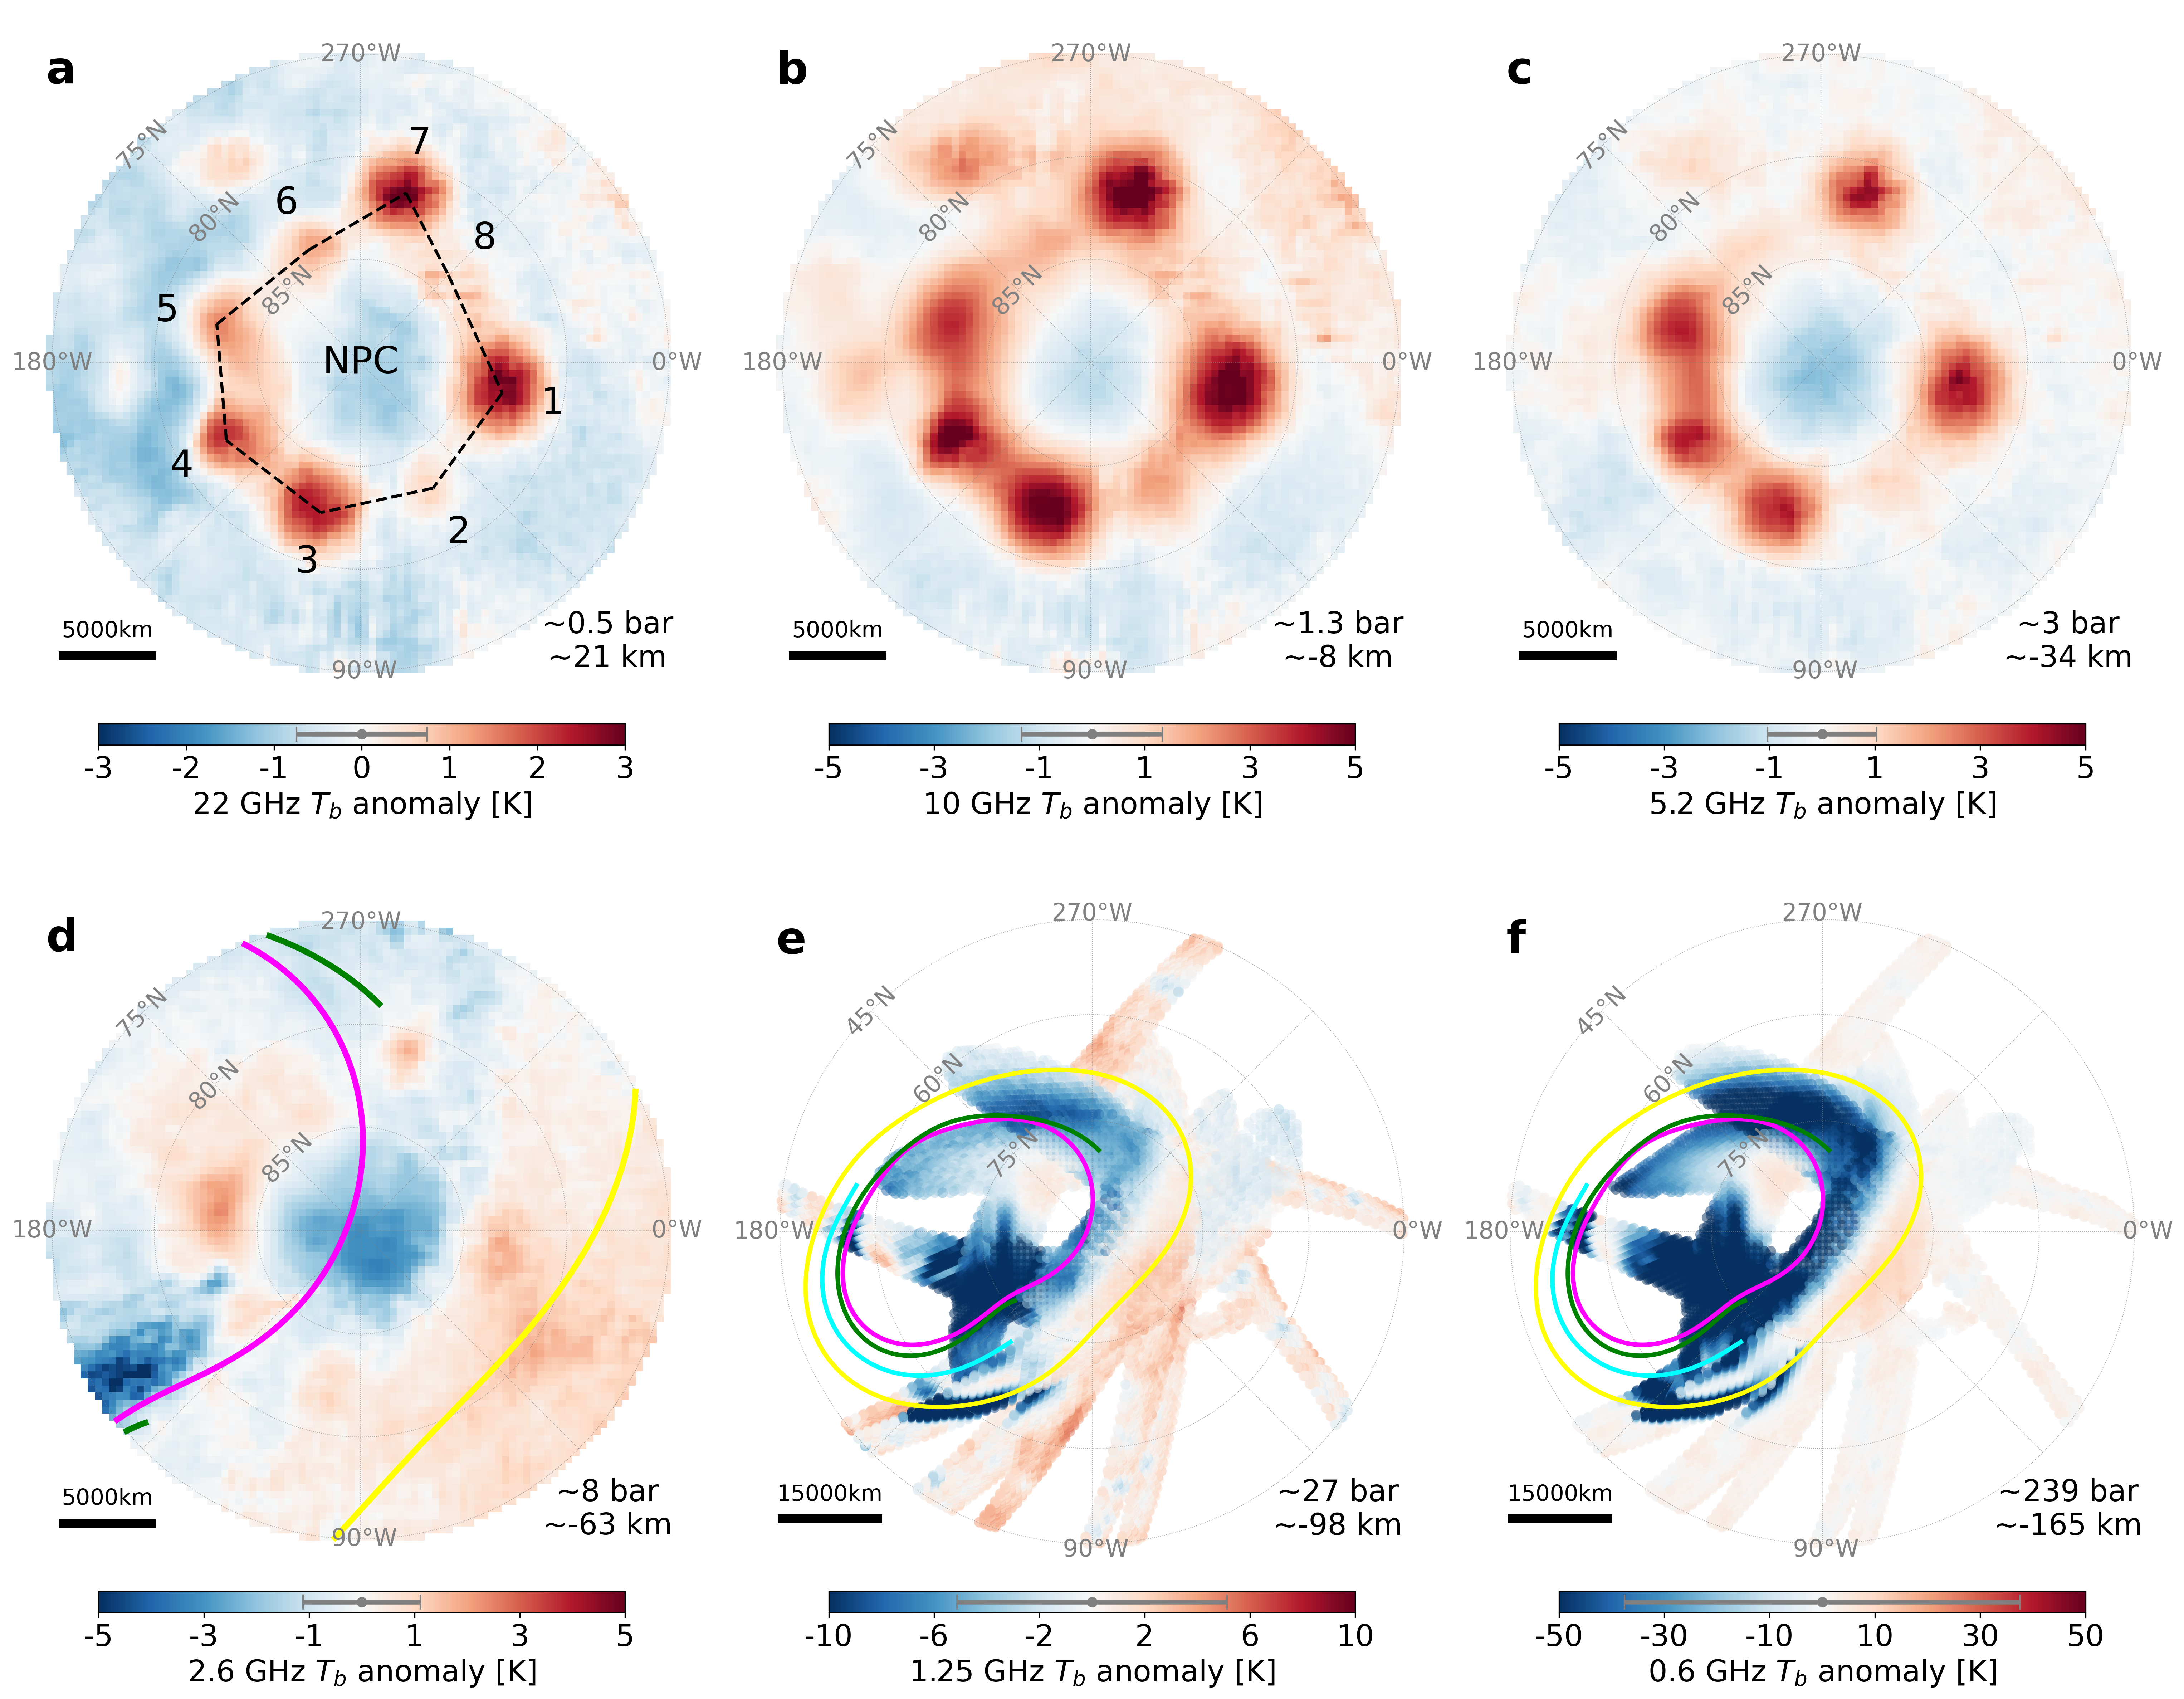

In [12]:
import matplotlib.pyplot as plt
import h5py
import numpy as np
import cartopy.crs as ccrs
from matplotlib.colors import BoundaryNorm
from matplotlib.cm import get_cmap
from scipy.ndimage import gaussian_filter

freqs=[0.6,1.25,2.6,5.2,10,22]
levels=[np.linspace(-50, 50, 11),
        np.linspace(-10, 10, 11),
        np.linspace(-5, 5, 11),
        np.linspace(-5, 5, 11),
        np.linspace(-5, 5, 11),
        np.linspace(-3, 3, 13)]



fig=plt.figure(figsize=(26, 21), dpi=300)

for ch in range(6):

        ax=fig.add_subplot(2, 3, 6-ch)

        cmap = 'RdBu_r'
        clevels=np.linspace(levels[ch][0], levels[ch][-1], 255)
        set_ax_cartesian(ax)
        # set_grid_ax(ax)

        if ch>1:
            with h5py.File("tb_anomaly_grided_PJ51_PJ61_FA02.h5", "r") as h5f:
                anomaly=h5f["anomaly"][:]
                lon2d=h5f["longitude"][:]
                lat2d=h5f["latitude"][:]
                grid_x=h5f["x"][:]
                grid_y=h5f["y"][:]

            # set grid
            set_grid_ax(ax)
            # add scalebar

            add_scalebar(ax, grid_x, grid_y)

            ax.pcolormesh(grid_x, grid_y, anomaly[ch], cmap=cmap,  vmin=levels[ch][0], vmax=levels[ch][-1], shading='auto')
            sc=ax.scatter([],[], c=[], cmap=cmap, vmin=levels[ch][0], vmax=levels[ch][-1])
            cbar = plt.colorbar(sc, ax=ax, orientation='horizontal', shrink=0.75, aspect=25, pad = 0.01, extend='neither')
            cbar.ax.errorbar(0,0.5, xerr=stddev[ch], fmt='o', color='gray', elinewidth=3, capsize=5, zorder=1000, clip_on=False)

        else: # ch1 ch2
                # read back and plot to verify
            with h5py.File("tb_anomaly_grided_PJ51_PJ61_FA02_lat45.h5", "r") as h5f:
                anomaly=h5f["anomaly"][:]
                lon2d=h5f["longitude"][:]
                lat2d=h5f["latitude"][:]
                grid_x=h5f["x"][:]
                grid_y=h5f["y"][:]

            # guassian smooth
            anomaly[ch] = gaussian_filter(anomaly[ch], sigma=0.3)

            # ax.pcolormesh(grid_x, grid_y, anomaly[ch], cmap=cmap,  vmin=levels[ch][0], vmax=levels[ch][-1], shading='auto')

            fulldisk=h5py.File("tb_anomaly_1d_PJ51_PJ61_FA02_lat45N.h5", "r")
            tb=fulldisk[f"ch{ch+1}"]["Tb"][:]
            lon=fulldisk[f"ch{ch+1}"]["lon"][:]
            lat=fulldisk[f"ch{ch+1}"]["lat"][:]
            fulldisk.close()

            xs,ys= trans_coordinates(lat, lon)

            ax.scatter(xs, ys, c=tb,  vmin=levels[ch][0], vmax=levels[ch][-1], cmap=cmap, s=50, alpha=0.5, edgecolor='none')
            ax.scatter(grid_x, grid_y, c= anomaly[ch], cmap=cmap,  vmin=levels[ch][0], vmax=levels[ch][-1], s=50, alpha=0.5, edgecolor='none')

            sc=ax.scatter([],[], c=[], cmap=cmap, vmin=levels[ch][0], vmax=levels[ch][-1])
            cbar = plt.colorbar(sc, ax=ax, orientation='horizontal', shrink=0.75, aspect=25, pad = 0.01, extend='neither')
            
            cbar.ax.errorbar(0,0.5, xerr=stddev[ch], fmt='o', color='gray', elinewidth=3, capsize=5, zorder=1000, clip_on=False)

            for ll in [45,60,75]:
                lons=np.linspace(-180, 180, 100)
                lats=np.linspace(ll, ll, 100)
                xg,yg=trans_coordinates(lats, lons)
                # if ll==75: lw=1 ; linestyle="-"; color='k'
                # else: 
                lw=0.5; linestyle=":"
                ax.plot(xg,yg,linestyle=linestyle, color='gray', lw=lw, alpha=0.7)
                
                x,y=trans_coordinates(ll, 135)
                ax.text(x,y, f"{ll:2.0f}°N", color='gray', va='center', ha="center", rotation=45, fontsize=16)


            for oo in np.linspace(0,315,8):
                lons=np.linspace(oo, oo, 100)
                lats=np.linspace(45, 90, 100)
                xg,yg=trans_coordinates(lats, lons)
                ax.plot(xg,yg,":", color='gray', lw=0.5, alpha=0.7)
                if oo%90==0:
                    x,y=trans_coordinates(44, oo)
                    ha="center"
                    va='center'
                    if oo==0: oo=360
                    ax.text(x,y, f"{360-oo:3.0f}°W", color='gray',  va=va, ha=ha, fontsize=16)
            ax.set_xlim(-5.5E4, 5.5E4)
            ax.set_ylim(-5.5E4, 5.5E4)
        

            scalebar_x = grid_x.min()+1200  # Adjust position (X-coordinate)
            scalebar_y = grid_y.min()+5000 # Adjust position (Y-coordinate)
            scalebar_width = 11000  # Adjust the thickness of the scale bar

            ax.plot([scalebar_x, scalebar_x + 15000], [scalebar_y, scalebar_y], color='black', lw=6)
            ax.text(scalebar_x + 7500, scalebar_y + scalebar_width/2, '15000km', ha='center', va='top', fontsize=15, color='black')


        ax.set_aspect('equal')
        ax.text(0.85, 0.06, f"~{[239,27,8,3,1.3,0.5][ch]} bar\n~{[-165,-98,-63,-34,-8,21][ch]} km", color='k', transform=ax.transAxes, fontsize=20, va='bottom', ha='center')  
        ax.text(0.05, 0.945, f"{chr(97+5-ch)}", transform=ax.transAxes, fontsize=30, fontweight='bold', va='top', ha='left')

        cbar.ax.tick_params(labelsize=20)
        cbar.ax.set_xticks(levels[ch][::2])
        cbar.set_label(rf"{freqs[ch]} GHz $T_b$ anomaly [K]", fontsize=20)
        cbar.ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:1.0f}'))
        cbar.ax.tick_params(axis='x', which='minor', bottom=False, top=False, labelbottom=False)



        def plot_aurora_cartesian(ax):    
                oval_path = "/home/ananyo/mwr_ftpt/Oval/Jup_expanded.txt"
                data = np.loadtxt(oval_path)
                ovlon = 0-data[:, 0]  # First column
                ovlat = data[:, 1]  # Second column
                # trans to x,y
                ovx, ovy= trans_coordinates(ovlat, ovlon)
                ax.plot(ovx, ovy, color='magenta', lw=3, label='Aurora')

                oval_path = "/home/ananyo/mwr_ftpt/Oval/Io_ref.txt"
                data = np.loadtxt(oval_path)
                ovlon = 0-data[:, 1]  # First column
                ovlat = data[:, 2]  # Second column
                ovx, ovy= trans_coordinates(ovlat, ovlon)
                ax.plot(ovx, ovy, color='yellow', lw=3, label='Aurora')

                oval_path = "/home/ananyo/mwr_ftpt/Oval/Europa_ref.txt"
                data = np.loadtxt(oval_path)
                ovlon = 0-data[:, 1]  # First column
                ovlat = data[:, 2]  # Second column
                ovx, ovy= trans_coordinates(ovlat, ovlon)
                ax.plot(ovx, ovy, color='cyan', lw=3, label='Aurora')

                oval_path = "/home/ananyo/mwr_ftpt/Oval/Ganymede_ref.txt"
                data = np.loadtxt(oval_path)
                ovlon = 0-data[:, 1]  # First column
                ovlat = data[:, 2]  # Second column
                ovx, ovy= trans_coordinates(ovlat, ovlon)
                ax.plot(ovx, ovy, color='green', lw=3, label='Aurora')

        def plot_aurora_ch3(ax):    
                oval_path = "/home/ananyo/mwr_ftpt/Oval/Jup_expanded.txt"
                data = np.loadtxt(oval_path)
                ovlon = 0-data[:, 0]  # First column
                ovlat = data[:, 1]  # Second column
                omsk = (ovlat > 75)
                mx,my=trans_coordinates(ovlat[omsk], ovlon[omsk])
                ax.plot(mx, my, color='magenta', lw=4, label='Main oval')

                oval_path = "/home/ananyo/mwr_ftpt/Oval/Io_ref.txt"
                data = np.loadtxt(oval_path)
                ovlon = 0-data[:, 1]  # First column
                ovlat = data[:, 2]  # Second column
                omsk = (ovlat > 75)
                mx,my=trans_coordinates(ovlat[omsk], ovlon[omsk])
                ax.plot(mx,my, color='yellow', lw=4, label='Io footprint')

                oval_path = "/home/ananyo/mwr_ftpt/Oval/Ganymede_ref.txt"
                data = np.loadtxt(oval_path)
                ovlon = 0-data[:, 1]  # First column
                ovlat = data[:, 2]  # Second column
                omsk = ((ovlat > 75) & (ovlon < -180)) | ((ovlat > 75) & (ovlon > 0))
                mx,my=trans_coordinates(ovlat[omsk], ovlon[omsk])
                ax.plot(mx,my, color='green', lw=4, label='Ganymede footprint')
                
                omsk=(ovlat>75) & (ovlon>-180) & (ovlon<0)
                mx,my=trans_coordinates(ovlat[omsk], ovlon[omsk])
                ax.plot(mx,my, color='green', lw=4, label='Ganymede footprint')

        def cpc_polygon(ax):
            lon_cpc = [15,348, 300, 255, 210, 165, 115, 75, 45, 15]
            lat_cpc = [84.3,83, 83, 82.5, 82.5, 82.8, 84, 81.5, 84, 84.3]
            for ic in range(len(lon_cpc)-1):
                lonc=[lon_cpc[ic],lon_cpc[ic+1]]; latc=[lat_cpc[ic], lat_cpc[ic+1]]
                xc,yc= trans_coordinates(latc, lonc)
                ax.plot(xc, yc, '--', alpha=1, linewidth=2, color='k', zorder=3)

            for ic in range(1,len(lon_cpc)-1):
                mx,my=trans_coordinates( lat_cpc[ic]-2.5, lon_cpc[ic])
                ax.text(mx, my, f"{ic}", fontsize=25, color="k", horizontalalignment='center', verticalalignment='center')
            ax.text(0, 0, "NPC", fontsize=25, color="k", horizontalalignment='center',  verticalalignment='center')


        if ch<2:
            plot_aurora_cartesian(ax)
        if ch==5:
            cpc_polygon(ax)
        if ch==2:
            plot_aurora_ch3(ax)




fig.subplots_adjust(hspace=0, wspace=0.04)

# plt.show()
fig.savefig("tb_anomaly.pdf", bbox_inches='tight', dpi=300)

In [1]:
# make polar area-weighted mean Tb maps for each channel
import numpy as np
import h5py
from scipy.interpolate import griddata

def trans_latlon_to_xy(lat, lon):
    # Jupiter's radii in km
    R_equator = 71492.0  # Equatorial radius
    R_polar = 66854.0    # Polar radius

    # Convert lat and lon to radians
    lat_rad = np.radians(lat)
    lon_rad = np.radians(lon)

    # Calculate the radius for each latitude (ellipsoidal shape of Jupiter)
    R = R_equator * np.cos(lat_rad)**2 + R_polar * np.sin(lat_rad)**2

    # Compute Cartesian coordinates
    x = R * np.cos(lat_rad) * np.cos(lon_rad)
    y = R * np.cos(lat_rad) * np.sin(lon_rad)

    return x, y


def sph_area_triangle(p1, p2, p3):
    """计算单位球面上由三点组成的球面三角形面积"""
    a = np.array(p1)
    b = np.array(p2)
    c = np.array(p3)
    N = np.dot(a, np.cross(b, c))
    D = 1 + np.dot(a, b) + np.dot(b, c) + np.dot(c, a)
    return 2 * np.arctan2(N, D)

def sph_to_xyz(lon, lat):
    lon, lat = np.deg2rad(lon), np.deg2rad(lat)
    return [np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)]

from scipy.optimize import fsolve
def inverse(phi, rc):
    R_equator = 71492.0  # Equatorial radius
    R_polar = 66854.0    # Polar radius
    return (R_equator * np.cos(phi)**2 + R_polar * np.sin(phi)**2) * np.cos(phi) - rc

def quad_area(lonlat, R):
    # lonlat = [(lon1,lat1), (lon2,lat2), (lon3,lat3), (lon4,lat4)]
    xyz = [sph_to_xyz(lon, lat) for lon, lat in lonlat]
    E1 = sph_area_triangle(xyz[0], xyz[1], xyz[2])
    E2 = sph_area_triangle(xyz[0], xyz[2], xyz[3])
    return abs(E1 + E2) * R**2

R_jup = 66854.0       # Jupiter radius in km


def trans_xy_to_lonlat(x,y):
    """
    Convert Cartesian coordinates (x, y) to longitude and latitude.
    """
    lon = np.arctan2(y, x)  # Longitude
    rc= np.sqrt(x**2 + y**2)

    phi_guess = np.radians(30)
    
    phi_solution = fsolve(inverse, phi_guess, args=(rc,))
    # Convert to degrees
    lat = phi_solution[0]
    if lon >180:
        lon = 2 * np.pi-lon

    return np.degrees(lon), np.degrees(lat)

stddev=[]
h5file=h5py.File("tb_anomaly_1d_PJ51_PJ61_FA02.h5", "r")
for ch in range(1,7):
    tb=h5file[f"ch{ch}"]["Tb"][:]
    lon=h5file[f"ch{ch}"]["lon"][:]
    lat=h5file[f"ch{ch}"]["lat"][:]
    ax=ch-1

    x,y= trans_latlon_to_xy(lat, lon)
    # Create a grid for contour plotting
    # X, Y = np.meshgrid(x, y)

    # Create a regular grid for interpolation
    grid_x, grid_y = np.meshgrid(
        np.linspace(x.min(), x.max(), 100),  # Grid resolution along X
        np.linspace(y.min(), y.max(), 100)  # Grid resolution along Y
    )

    # tb = gaussian_smoothing(x, y, tb, sigma=0.001)

    grid_tb = griddata((x, y), tb, (grid_x, grid_y), method='linear')
    # grid_tb = gaussian_filter(grid_tb, sigma=0.7)

    grid_lonlat = np.array([trans_xy_to_lonlat(x, y) for x, y in zip(grid_x.flatten(), grid_y.flatten())])
    grid_lon = grid_lonlat[:, 0].reshape(grid_x.shape) # Reshape
    grid_lat = grid_lonlat[:, 1].reshape(grid_x.shape)  # Reshape


    distance_to_origin = np.sqrt(grid_x**2 + grid_y**2)
    x75,y75=trans_latlon_to_xy(74.8, 0)
    dist75 = np.sqrt(x75**2 + y75**2)
    grid_tb[distance_to_origin > dist75] = np.nan     

    ny, nx = grid_x.shape
    dA = np.zeros((ny, nx))
    for i in range(ny-1):
        for j in range(nx-1):

            lonlat = [(grid_lon[i,j], grid_lat[i,j]),
                    (grid_lon[i,j+1], grid_lat[i,j+1]),
                    (grid_lon[i+1,j+1], grid_lat[i+1,j+1]),
                    (grid_lon[i+1,j], grid_lat[i+1,j])]
            dA[i,j] = quad_area(lonlat, R_jup)

    dA[-1,:] = dA[-2,:]
    dA[:,-1] = dA[:,-2]
            # dlam = np.deg2rad(grid_lon[i,j+1]-grid_lon[i,j]) if j<nx-1 else np.deg2rad(grid_lon[i,nx-1]-grid_lon[i,nx-2])
            # dphi_sin = np.sin(np.deg2rad(grid_lat[i+1,j])) - np.sin(np.deg2rad(grid_lat[i,j]))
            # dA[i,j] = R_jup**2 * dlam * dphi_sin

    dA[dA<1E5]=np.nan  # Mask very small areas
    dA[distance_to_origin > dist75] = np.nan  # Mask areas outside 75°N

    mean_Tb = np.nansum(grid_tb * dA)/ np.nansum(dA)

    # compute the area-weighted standard deviation
    std_Tb = np.sqrt(np.nansum(((grid_tb - mean_Tb)**2) * dA)/ np.nansum(dA))
    print(f"Channel {ch} area-weighted Tb std. dev.: ± {std_Tb:.2f} K")
    stddev.append(std_Tb)

Channel 1 area-weighted Tb std. dev.: ± 37.53 K
Channel 2 area-weighted Tb std. dev.: ± 5.13 K
Channel 3 area-weighted Tb std. dev.: ± 1.11 K
Channel 4 area-weighted Tb std. dev.: ± 1.04 K
Channel 5 area-weighted Tb std. dev.: ± 1.33 K
Channel 6 area-weighted Tb std. dev.: ± 0.74 K


In [ ]:
# import matplotlib.pyplot as plt
# import cartopy.crs as ccrs
# from matplotlib.colors import BoundaryNorm
# from matplotlib.cm import get_cmap

# freqs=[0.6,1.25,2.6,5.2,10,22]
# levels=[np.linspace(-20, 20, 11),
#         np.linspace(-5, 5, 11),
#         np.linspace(-5, 5, 11),
#         np.linspace(-5, 5, 11),
#         np.linspace(-5, 5, 11),
#         np.linspace(-3, 3, 13)]


# fig=plt.figure(figsize=(28, 20), dpi=300)

# for ch in range(6):
#         if ch<2:
#             ax=fig.add_subplot(2, 3, 6-ch, projection=ccrs.NearsidePerspective(central_longitude=-90, central_latitude=56.0, satellite_height=35785831))
#         else:
#             ax=fig.add_subplot(2, 3, 6-ch, projection=ccrs.NearsidePerspective(central_longitude=-90, central_latitude=70.0, satellite_height=35785831))
#         # extent = ax.get_extent()
#         # ax2.set_xlim(extent[:2])
#         # ax2.set_ylim(extent[3],extent[3])
#         gl2=ax.gridlines(draw_labels=False, linewidth=1, color='k', alpha=0.5, linestyle='--', zorder=4)
#         gl2.xlocator = plt.FixedLocator([])
#         gl2.ylocator = plt.FixedLocator([75, 80, 85, 90])
#         for spine in ax.spines.values():
#             spine.set_visible(False)

#         labelsize=16
#         clr='gray'
#         alp=1
#         ax.text(-45,90, r"$\circ$", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#         ax.text(-45,75, "75°N", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#         ax.text(-45,80, "80°N", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#         ax.text(-45,85, "85°N", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())

#         ax.text(0 , 74.2, "0°", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#         ax.text(-90, 74.2, "90°W", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#         ax.text(90, 74.2, "270°W", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#         ax.text(180, 74.2, "180°W", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())

#         ax.plot([-135]*100, np.linspace(73,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)
#         ax.plot([-45]*100, np.linspace(73,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)
#         ax.plot([135]*100, np.linspace(73,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)
#         ax.plot([45]*100, np.linspace(73,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)

#         ax.plot([90]*100, np.linspace(73,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)
#         ax.plot([-90]*100, np.linspace(73.5,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)

#         ax.plot([0]*100, np.linspace(73,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)
#         ax.plot([180]*100, np.linspace(73,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)      


#         cmap = get_cmap('RdBu_r', 255)
#         clevels=np.linspace(levels[ch][0], levels[ch][-1], 255)
#         norm = BoundaryNorm(clevels, ncolors=255, clip=True)

#         if ch>1:
#             sc = ax.scatter(lon2d, lat2d, c=anomaly[ch],  norm=norm, cmap=cmap, transform= ccrs.PlateCarree(), s=50, alpha=1, edgecolor='none')
#             cbar = plt.colorbar(sc, ax=ax, orientation='horizontal', shrink=0.65, aspect=30, pad = -0.05, extend='both')
            
#             ax.text(0.85, 0.1, f"~{[120,25,8,3,1.3,0.5][ch]} bar\n~{[-140,-90,-60,-30,-8,20][ch]} km", color='k', transform=ax.transAxes, fontsize=20,  va='bottom', ha='center', fontweight='bold')  
#         else: # ch1 ch2
#             fulldisk=h5py.File("tb_anomaly_1d_PJ51_PJ61_FA02_lat45N.h5", "r")
#             tb=fulldisk[f"ch{ch+1}"]["Tb"][:]
#             lon=fulldisk[f"ch{ch+1}"]["lon"][:]
#             lat=fulldisk[f"ch{ch+1}"]["lat"][:]
#             fulldisk.close()
#             ax.scatter(lon, lat, c=tb,  norm=norm, cmap=cmap, transform= ccrs.PlateCarree(), s=20, alpha=0.5, edgecolor='none')
#                     # Add colorbar
#             sc = ax.scatter([], [], c=[], norm=norm, cmap=cmap, transform= ccrs.PlateCarree(), s=20, alpha=1, edgecolor='none')
#             cbar = plt.colorbar(sc, ax=ax, orientation='horizontal', shrink=0.65, aspect=30, pad = 0.02, extend='both')


#             gl2.ylocator = plt.FixedLocator([45, 60, 75, 90])
#             gl2.xlocator = plt.FixedLocator([-180 , -90, 0, 45, 90, 135, 180])
#             labelsize=16
#             clr='gray'
#             alp=1
#             ax.text(-45,90, r"$\circ$", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#             ax.text(-45,75, "75°N", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#             ax.text(-45,60, "60°N", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#             ax.text(-45,45, "45°N", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())

#             ax.text(0 , 43, "0°", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#             ax.text(-90, 43, "90°W", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#             ax.text(90, 43, "270°W", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#             # x2.text(-120, 45, "120°W", color='k', fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())
#             ax.text(180, 43, "180°W", color=clr, alpha=alp, fontsize=labelsize, va='center',ha="center", transform=ccrs.PlateCarree())

#             ax.plot([-135]*100, np.linspace(40,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)
#             ax.plot([-45]*100, np.linspace(40,90, 100), 'k--', lw=1, alpha=0.5, transform=ccrs.Geodetic(), zorder=3)

#             ax.plot(np.linspace(-180, 180, 720), [75]*720, color="k", linestyle='--', lw=2, alpha=1, transform=ccrs.Geodetic(), zorder=3)

#             plot_aurora_cartesian(ax)  
            
#             ax.text(0.85, 0.02, f"~{[120,25,8,3,1.3,0.5][ch]} bar\n~{[-140,-90,-60,-30,-8,20][ch]} km", color='k', transform=ax.transAxes, fontsize=20,  va='bottom', ha='center', fontweight='bold')  

#         cbar.ax.tick_params(labelsize=20)
#         cbar.ax.set_xticks(levels[ch][::2])
#         cbar.set_label(rf"{freqs[ch]} GHz $T_b$ anomaly [K]", fontsize=20)
#         cbar.ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:1.0f}'))
#         cbar.ax.tick_params(axis='x', which='minor', bottom=False, top=False, labelbottom=False)

#         if ch==2:
#             plot_aurora_ch3(ax)
#         if ch==5:
#             cpc_polygon(ax)



#         ax.text(0.05, 0.945, f"{chr(97+6-ch)}", transform=ax.transAxes, fontsize=30, fontweight='bold', va='top', ha='left')

# fig.subplots_adjust(hspace=-0.15, wspace=0.02)